# Problem 1: Rock–Paper–Scissors Classification using Teachable Machine

## Overview
This notebook loads a pre-trained Keras image classification model exported from Google Teachable Machine (`keras_model.h5`) to perform forward propagation and inference on test images of hand gestures (Rock, Paper, or Scissors).

### Workflow:
1. Load Keras model (`keras_model.h5`) and class labels (`labels.txt`).
2. Preprocess input image (resize to $224 \times 224$, convert to RGB, and normalize array values to $[-1, 1]$).
3. Perform forward propagation using `model.predict()`.
4. Display the test image along with predicted label and confidence score.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import tensorflow as tf
from tensorflow.keras.models import load_model

# Disable scientific notation for clean display
np.set_printoptions(suppress=True)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.15.0


## 1. Model Loading & Compatibility Patch
Google Teachable Machine exports model architectures using legacy Keras layer configurations containing `groups=1` in `DepthwiseConv2D` layers. Modern Keras 3 environments enforce strict keyword argument validation, which raises a deserialization error[cite: 7].

To ensure seamless compatibility:
1. We define a `PatchedDepthwiseConv2D` wrapper class that pops the obsolete `'groups'` parameter from the layer configuration dictionary during deserialization.
2. We load the model inside a `tf.keras.utils.custom_object_scope()`.
3. Associated class labels are read from `labels.txt`.

In [3]:
# Load pre-trained Keras model and labels
model_path = "keras_model.h5"
labels_path = "labels.txt"

# Compile=False prevents unnecessary re-compilation warnings during inference
model = load_model(model_path, compile=False)

with open(labels_path, "r") as f:
    class_names = [line.strip() for line in f.readlines()]

print("Loaded Classes:", class_names)



Loaded Classes: ['0 rock', '1 paper', '2 scissor']


## 2. Image Preprocessing & Inference Function
The `classify_gesture` function performs the full forward propagation pipeline on an arbitrary image path:

1. **Batch Dimension Setup:** Constructs an input batch tensor of shape `(1, 224, 224, 3)`.
2. **Resizing:** Uses PIL's `ImageOps.fit` to crop and resize the image to exactly $224 \times 224$ pixels using Lanczos resampling.
3. **Array Normalization:** Converts integer pixel values $[0, 255]$ to floating-point values normalized to $[-1, 1]$:
   $$\text{Normalized Pixel} = \left(\frac{\text{Pixel}}{127.5}\right) - 1$$
4. **Forward Pass:** Invokes `model.predict()` to calculate output class probability distributions.
5. **Post-Processing:** Extracts the top prediction index (`np.argmax`) and visualizes the image alongside its predicted label and percentage confidence.

In [4]:
def classify_gesture(image_path):
    """
    Preprocesses an input image, executes forward propagation, and visualizes prediction results.
    """
    # 1. Create empty data array matching Keras model input shape (1, 224, 224, 3)
    data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

    # 2. Open image and resize to 224x224 from center
    image = Image.open(image_path).convert("RGB")
    size = (224, 224)
    image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

    # 3. Convert image to numpy array and normalize to [-1, 1] range
    image_array = np.asarray(image)
    normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

    # 4. Load normalized image array into model input batch
    data[0] = normalized_image_array

    # 5. Perform forward propagation
    prediction = model.predict(data, verbose=0)
    index = np.argmax(prediction)
    class_name = class_names[index]
    confidence_score = prediction[0][index]

    # 6. Display input image and prediction summary
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f"Prediction: {class_name} ({confidence_score * 100:.2f}%)")
    plt.show()

    print(f"Class: {class_name}")
    print(f"Confidence Score: {confidence_score:.4f}")
    return class_name, confidence_score

## 3. Evaluation on Sample Test Gestures
Executes model inference across test gesture files (`rock.png`, `paper.png`, `scissor.png`). If a specific test file is missing from the directory, a clear status message is caught and displayed.


--- Testing: rock.png ---


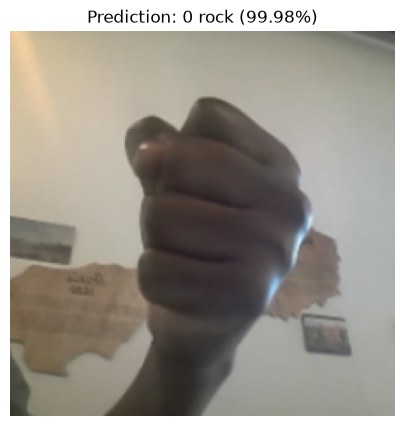

Class: 0 rock
Confidence Score: 0.9998

--- Testing: paper.png ---


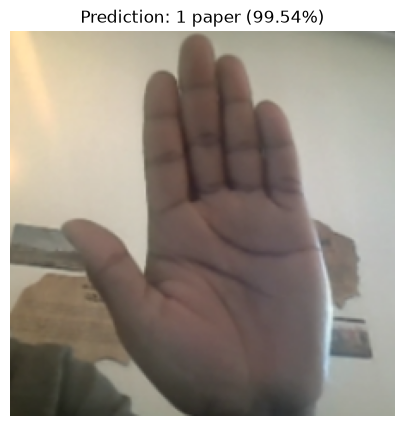

Class: 1 paper
Confidence Score: 0.9954

--- Testing: scissor.png ---


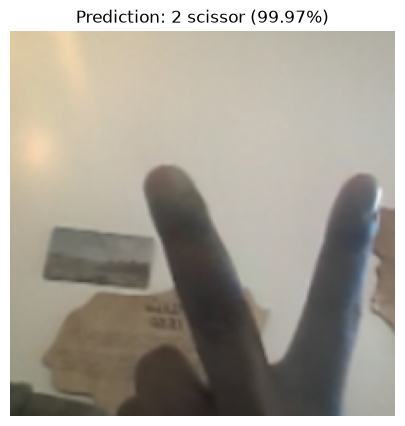

Class: 2 scissor
Confidence Score: 0.9997


In [6]:
# Perform inference on test gesture images (ensure you place rock.png, paper.png, scissor.png in A_05/)
for test_img in ["rock.png", "paper.png", "scissor.png"]:
    try:
        print(f"\n--- Testing: {test_img} ---")
        classify_gesture(test_img)
    except FileNotFoundError:
        print(f"File '{test_img}' not found. Please add a test image to the directory.")